# Charging-to-Adoption: Can Public EV Chargers Lead Electric-Car Adoption?
### Global EV infrastructure demand factor · Research-grade retrospective pilot · 19 October 2026

**Study type:** historical national-market *demand* prediction; **NOT an investable equity-alpha backtest**.  
**Frozen data:** IEA *Global EV Outlook 2024* historical EV sales shares and public charging-point counts, selected 16-country extract.  
**Research question:** do public charging additions contain *incremental* information about subsequent EV sales-share growth beyond adoption persistence?

**Headline:** 96 expanding-window OOS country-year forecasts, controls RMSE **4.483 pp**, full charging model **4.468 pp**, simple momentum **4.416 pp**. The full model is not best-in-class. Placebo p≈0.132 and bootstrap uncertainty crosses zero. **No tradable alpha demonstrated.**

## 01. Abstract


### Abstract

Charging availability may reduce range anxiety, increase EV convenience and ultimately stimulate adoption. The competing explanation is **reverse causality**: public chargers are installed in response to an already-growing EV fleet. We build a deterministic country-level annual factor from *t−1* charging-point growth and test whether it forecasts year-*t* EV sales-share change after controls. We use a fixed historical 2024 IEA snapshot, a six-year expanding-window OOS evaluation, multiple forecasting baselines, year-stratified feature-shuffle placebos, calendar-year block bootstrap, ablations and country-removal tests. This is a **retrospective association study**, not a vintage-correct strategy.

## 02. Research Design & Hypotheses


#### 1.1 · Mechanism and countermechanism

**Supply complementarity:** chargers can make EVs usable for drivers without home charging and enable longer journeys. **Network externalities:** broader networks reduce perceived risk of EV ownership. **Endogeneity:** governments and operators often build chargers where demand is already rising. **Confounders:** purchase incentives, battery costs, model availability, electricity prices and policy phase-outs jointly influence EV share and infrastructure.

The research deliberately evaluates *predictive incrementality*, not causal impact.

#### 1.2 · Falsifiable hypotheses

- **H1 (direction):** lagged charging growth has positive cross-country association with future EV sales-share change.
- **H2 (incremental forecast):** charging features improve expanding-window OOS RMSE against a fixed country/persistence/trend model and a simple momentum benchmark.
- **H3 (robustness):** any improvement survives placebo, ablation, leave-one-country-out, regime and time-lag checks.

Failure to beat momentum or to survive placebo means **no robust alpha claim**.

## 03. Industry Context


### 1 · Economic thesis and structural demand

The IEA's *Global EV Outlook 2024*, **published 23 April 2024**, estimated nearly **14 million** electric-car sales in 2023, or **18%** of global new-car sales. The IEA reported roughly **40%** year-over-year growth in installed public charging points in 2023. These are *industry-level observations*, not the backtest's forecast outcomes or evidence of equity alpha.

Primary source: [IEA Global EV Outlook 2024](https://www.iea.org/reports/global-ev-outlook-2024). EV affordability, subsidies, charging uptime and grid access can all modify the relationship.

## 04. Data & Source Integrity


### 2 · Data provenance, hierarchy and vintages

**A** = official institutional publication; **B** = attributed, independently accessible mirror or derived extract; **C** = press/descriptive only. Official IEA report is A. Our *data file* is B because it is a third-party GitHub mirror of an IEA 2024 release, not a certified original binary.

The 2024 IEA data file was accessed on 2026-10-19. Its publication label is 2024, but the GitHub mirror's original upload timestamp, original release hash and historical revisions are **not authenticated**. Historical annual values observed in a 2024 snapshot cannot be treated as known in 2018. This is a material **point-in-time failure**, explicitly retained in the verdict.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from ev_charging_alpha import read_data, panel, walk_forward, metrics, per_year_rank_ic, country_leaveout, run
from plot_results import create_all_figures
pd.set_option('display.max_columns', 30)
summary,oos,feature_panel=run(draws=1000,write=True)
print('Analysis run completed: ',len(oos),'OOS observations')

Analysis run completed:  96 OOS observations


In [2]:
source_register=pd.read_csv('source_register.csv')
display(source_register[['dataset','grade','publication_date','observation_coverage','revision_vintage_status']])

,dataset,grade,publication_date,observation_coverage,revision_vintage_status
0,IEA Global EV Outlook 2024,A,2024-04-23,2023 world statistics and 2024 outlook,2024 report is not a series of real-time vintages
1,IEA Global EV Data 2024 country series,B,2024-04-23,Selected countries 2011-2023,Third-party mirror; original file hash and his...
2,Derived 16-country annual EV panel,B,2024-04-23,180 country-years 2011-2023,Selected rows rounded to at most 5 decimals fo...


#### 2.1 · Country-market exposure mapping

The observational unit is **country × year**. Country EV sales share is the outcome; public fast/slow charger growth is the exposure. The 16 selected markets are named in the source extract methodology; aggregate EU27/World rows are excluded to avoid double counting. This is *not* a map of public companies' revenue exposure. We do **not** assign fabricated issuer revenue weights or claim stock-return information coefficients.

In [3]:
raw=read_data()
coverage=raw.groupby('country').agg(first=('year','min'),last=('year','max'),n=('year','size'),share_2023=('ev_sales_share_pct','last'))
display(coverage)
print('Observations:',len(raw),'countries:',raw.country.nunique(),'years:',raw.year.min(),'-',raw.year.max())

,first,last,n,share_2023
country,,,,
Belgium,2013,2023,11,41.0
Canada,2012,2023,12,13.0
China,2014,2023,10,38.0
Denmark,2012,2023,12,46.0
Finland,2013,2023,11,54.0
France,2012,2023,12,25.0
Germany,2012,2023,12,24.0
Italy,2012,2023,12,9.2
Japan,2014,2023,10,3.6


Observations: 180 countries: 16 years: 2011 - 2023


#### 2.2 · Data-quality audit

Exact field filters are documented in `data/extract_methodology.md`. Missing fast/slow observations are **not imputed as zero**; only complete country-years are included. EV sales share is expressed in **percentage points**, not a decimal fraction. Charging data are counts of public points, **not uptime-adjusted usable capacity**. Small/zero counts can make log growth unstable; the factor applies a fixed bounded transform rather than full-sample normalization.

In [4]:
assert len(raw)==180 and raw.country.nunique()==16
assert not raw.duplicated(['country','year']).any()
assert raw.ev_sales_share_pct.between(0,100).all()
assert (raw[['public_fast_points','public_slow_points']]>=0).all().all()
display(raw[['ev_sales_share_pct','public_fast_points','public_slow_points']].describe(percentiles=[.05,.5,.95]).round(2))

,ev_sales_share_pct,public_fast_points,public_slow_points
count,180.00,180.00,180.00
mean,9.91,21068.78,43695.28
std,16.49,114059.80,149479.70
min,0.03,1.00,250.00
5%,0.14,16.65,796.00
50%,2.60,1050.00,8950.00
95%,39.10,28750.00,140000.00
max,93.00,1200000.00,1500000.00


## 05. Point-in-Time Availability


### 3 · Point-in-time design (conservative lag, incomplete vintage audit)

For an origin in calendar year *t*, features use annual observations no later than *t−1*. The annual target is `share_t − share_(t−1)`. When forecasting year *t*, model training labels come from years ≤ *t−1*; horizon-2 tests enforce an additional embargo. This blocks direct future-target leakage in code. **It does not reconstruct historical IEA releases**; all source values remain retrospectively revised/compiled in 2024. No historical trade execution date is claimed.

## 06. Factor Construction


#### 3.1 · Factor equations

For country $i$ and forecast year $t$:

$$F^{fast}_{i,t}=\log(1+Fast_{i,t-1})-\log(1+Fast_{i,t-2})$$
$$F^{slow}_{i,t}=\log(1+Slow_{i,t-1})-\log(1+Slow_{i,t-2})$$
$$Mix_{i,t}=\frac{Fast_{i,t-1}}{Fast_{i,t-1}+Slow_{i,t-1}}$$
$$Score_{i,t}=0.5\tanh(F^{fast}_{i,t})+0.5\tanh(F^{slow}_{i,t})$$
$$Y_{i,t}=EVShare_{i,t}-EVShare_{i,t-1}\quad\text{(percentage points)}$$

All scales/weights are fixed *ex ante*, not fitted to equity returns.

In [5]:
features=panel(raw)
assert features.year.min()>=2013
assert features.groupby(['country','year']).size().max()==1
print('Complete feature rows:',len(features))
display(features[['country','year','share_l1','delta_l1','fast_log_growth_l1','slow_log_growth_l1','fast_mix_l1','target_pp']].head(12).round(3))

Complete feature rows: 148


,country,year,share_l1,delta_l1,fast_log_growth_l1,slow_log_growth_l1,fast_mix_l1,target_pp
0,Norway,2013,3.100,1.700,1.133,0.177,0.015,2.700
1,Portugal,2013,0.088,-0.022,0.134,0.000,0.006,0.082
2,Canada,2014,0.220,0.080,0.981,0.510,0.006,0.130
3,Denmark,2014,0.280,-0.010,2.657,0.095,0.054,0.620
4,France,2014,0.530,0.200,2.313,0.753,0.056,0.160
5,Germany,2014,0.230,0.120,0.927,0.470,0.019,0.220
6,Italy,2014,0.080,0.047,1.253,0.000,0.004,0.020
7,Netherlands,2014,5.500,4.500,0.000,0.728,0.004,-1.600
8,Norway,2014,5.800,2.700,0.497,0.196,0.021,9.200
9,Portugal,2014,0.170,0.082,0.811,0.087,0.014,0.030


#### 3.2 · Data transformations and saturation

The `log1p` transform is well-defined for nonnegative charger counts. Fast and slow growth are kept separate in the regression to test whether fast-charging availability has additional explanatory value. The bounded composite score is used only for descriptive cross-sectional rank correlations and weight sensitivity. It is not an optimized security factor.

In [6]:
display(features[['share_l1','delta_l1','fast_log_growth_l1','slow_log_growth_l1','fast_mix_l1','target_pp']].describe(percentiles=[.1,.5,.9]).round(3))

,share_l1,delta_l1,fast_log_growth_l1,slow_log_growth_l1,fast_mix_l1,target_pp
count,148.000,148.000,148.000,148.000,148.000,148.000
mean,8.857,2.586,0.526,0.319,0.134,3.058
std,15.060,3.946,0.510,0.321,0.103,4.350
min,0.080,-4.000,-0.845,-0.069,0.004,-7.000
10%,0.338,-0.010,0.045,0.000,0.020,-0.003
50%,2.600,0.700,0.411,0.259,0.112,1.050
90%,26.000,8.000,1.218,0.682,0.286,9.440
max,89.000,19.000,2.657,2.206,0.432,19.000


## 07. Exposure & Transmission


### 4 · Industry heterogeneity: adoption curves

National markets differ sharply: Norway is near saturation while Japan's EV sales share remains much lower. A pooled correlation could mistake this market maturity effect for an infrastructure lead. This motivates country controls, leave-one-market-out diagnostics and regime splits.

Rendered 8 actual-data PNG figures


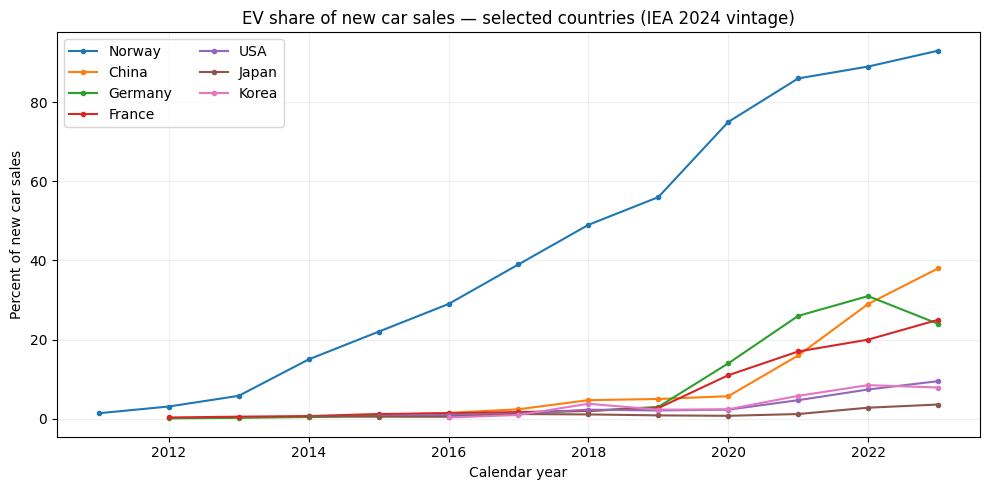

In [7]:
paths=create_all_figures()
assert len(paths)==8
print('Rendered',len(paths),'actual-data PNG figures')
display(Image(filename=paths[0],width=820))

#### 4.1 · Fast/slow charging composition

Installed charger counts differ by national definitions, population, fleet size and public-vs-private infrastructure. The fast share is not a normalized charger-per-EV or charger-per-capita measure. Without those denominators, cross-country comparisons can confound scale with adoption.

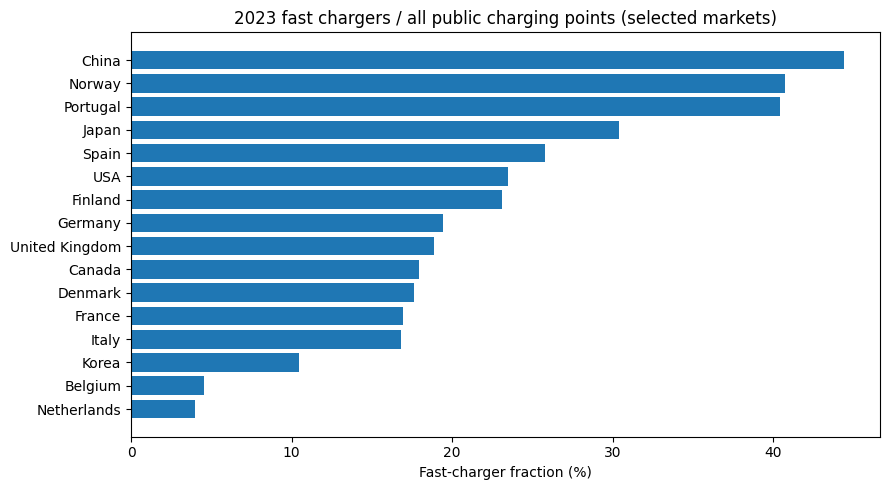

In [8]:
display(Image(filename=paths[1],width=800))

#### 4.2 · Preliminary cross-section is descriptive

A single-year scatter is shown to identify nonlinearities and influential markets, not to declare a statistically significant lead. The 2023 outcome uses 2022 charger data. Year-specific Spearman rank correlation is evaluated below.

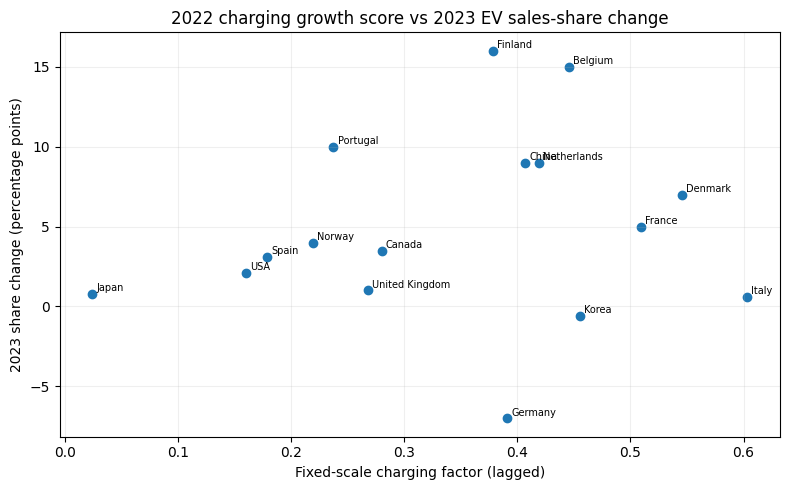

In [9]:
display(Image(filename=paths[2],width=800))

## 08. Outcomes & Baselines


### 5 · Out-of-sample design

The **six test years** are 2018–2023. For each year, a model is trained only on earlier labelled years, with all numeric standardization fit exclusively to that training set. The 16-country universe is fixed, Ridge penalty **α=10** is fixed without hyperparameter optimization, and no test outcomes enter model fitting. All 96 held-out observations are reported, not just a winning subsample.

**Comparators:** pooled historical mean, historical country mean, last observed EV-share change (momentum), Ridge country/lagged-share/lagged-change/calendar-trend controls, and the same Ridge with charging growth and fast mix.

In [10]:
assert len(oos)==96
print('OOS years:',sorted(oos.year.unique().tolist()),'rows:',len(oos))
display(oos.tail(10).round(3))

OOS years: [2018, 2019, 2020, 2021, 2022, 2023] rows: 96


,country,year,actual,charger_score,mean,country_mean,momentum,controls,full,no_fast,no_slow,no_mix
86,Germany,2023,-7.0,0.391,2.834,3.419,5.0,6.289,6.527,6.434,6.534,6.368
87,Italy,2023,0.6,0.603,2.834,0.947,-0.9,3.050,3.590,3.169,3.600,3.457
88,Japan,2023,0.8,0.024,2.834,0.326,1.6,3.643,3.586,3.550,3.567,3.664
89,Korea,2023,-0.6,0.455,2.834,1.510,2.7,4.385,4.741,4.696,4.763,4.414
90,Netherlands,2023,9.0,0.419,2.834,2.278,7.0,6.509,7.049,6.835,7.057,6.678
91,Norway,2023,4.0,0.220,2.834,8.590,3.0,7.889,7.671,7.827,7.685,7.768
92,Portugal,2023,10.0,0.237,2.834,2.191,2.0,4.771,4.533,4.680,4.560,4.685
93,Spain,2023,3.1,0.179,2.834,1.088,1.1,3.778,3.673,3.964,3.718,3.534
94,USA,2023,2.1,0.160,2.834,1.068,2.7,4.281,4.308,4.217,4.293,4.356
95,United Kingdom,2023,1.0,0.268,2.834,2.538,4.0,5.542,5.691,5.665,5.699,5.560


#### 5.1 · Evaluation metrics

RMSE and MAE are measured in **percentage points of EV new-car sales share**. They are not return percentages, Sharpe ratios, information ratios or tradable spreads. Report both global and country-specific naïve baselines to guard against spurious improvement over an easy benchmark.

In [11]:
scorecard=pd.DataFrame(summary['metrics']).T[['n','rmse_pp','mae_pp','bias_pp']]
display(scorecard.round(4))
print('Controls-minus-full RMSE:',round(summary['rmse_improvement_control_minus_full_pp'],5),'pp')

,n,rmse_pp,mae_pp,bias_pp
mean,96.0,5.1950,3.4228,-2.4612
country_mean,96.0,4.9549,3.3901,-2.6052
momentum,96.0,4.4156,2.9626,-0.6720
controls,96.0,4.4834,3.0909,-0.2328
full,96.0,4.4679,3.0788,-0.1438
no_fast,96.0,4.4905,3.0864,-0.1970
no_slow,96.0,4.4592,3.0762,-0.1550
no_mix,96.0,4.4696,3.0783,-0.1737


Controls-minus-full RMSE: 0.01552 pp


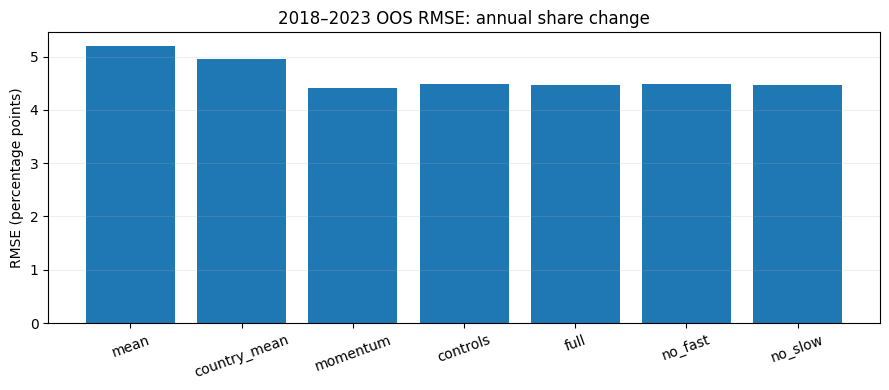

In [12]:
display(Image(filename=paths[3],width=800))

## 09. Empirical Findings


#### 5.2 · Primary verdict: negligible incrementality

Full charging model RMSE **4.468 pp** versus controls **4.483 pp**, a difference of only **0.016 pp**. Crucially, the simple momentum baseline is **4.416 pp**, better than the full model. The incremental model does not pass a credible practical-performance hurdle. This is a negative/weak result, not a positive investment signal.

### 6 · Cross-sectional rank IC (demand only)

For each OOS year, compute Spearman correlation across countries between the **lagged composite charger score** and that year's EV sales-share change. These ICs are **not equity-return ICs**. The small yearly cross-sections and common global policy shocks make nominal p-values unreliable; we report raw ICs without interpreting them as investable significance.

In [13]:
ic=per_year_rank_ic(oos)
display(ic.round(4))
print('Mean demand rank IC:',round(ic.rank_ic.mean(),4))

,year,n,rank_ic
0,2018,16,0.0529
1,2019,16,-0.0235
2,2020,16,0.0441
3,2021,16,-0.0029
4,2022,16,0.0914
5,2023,16,0.0927


Mean demand rank IC: 0.0425


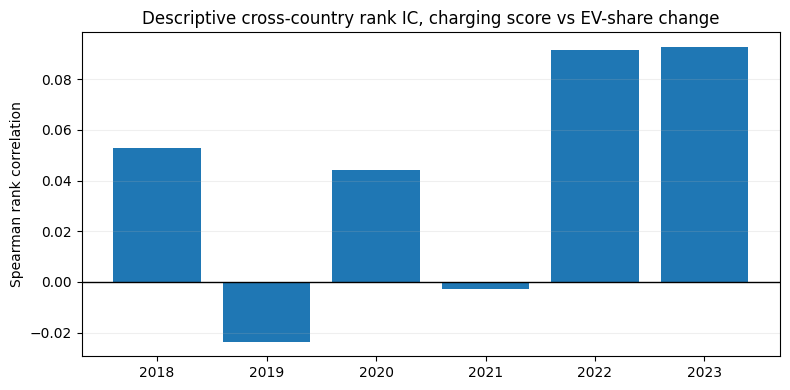

In [14]:
display(Image(filename=paths[4],width=800))

## 10. Robustness & Placebos


### 7 · Placebo: destroy charger/country pairing within each year

We permute **all three charging features jointly** across countries within each historical year and **refit every OOS model** for each of 1,000 permutations. This preserves yearly charging-feature distributions and feature co-movement, while breaking country-specific alignment. It does **not** preserve each country's serial correlation and cannot serve as an exact causal randomization test. We report an exploratory one-sided rank among placebo improvements.

In [15]:
print(json.dumps({k:v for k,v in summary['placebo'].items() if k!='null_distribution'},indent=2))
print('Permutation null draws saved to results/placebo_null_distribution.csv')

{
  "draws": 1000,
  "observed_delta_rmse_pp": 0.015515270632426414,
  "one_sided_p_exploratory": 0.13186813186813187,
  "null_q05_q50_q95": [
    -0.06124992431142391,
    -0.019356663515218475,
    0.03538092402156278
  ],
  "method": "Within-year cross-country charging-feature triplet shuffle, full refit; not causal randomization"
}
Permutation null draws saved to results/placebo_null_distribution.csv


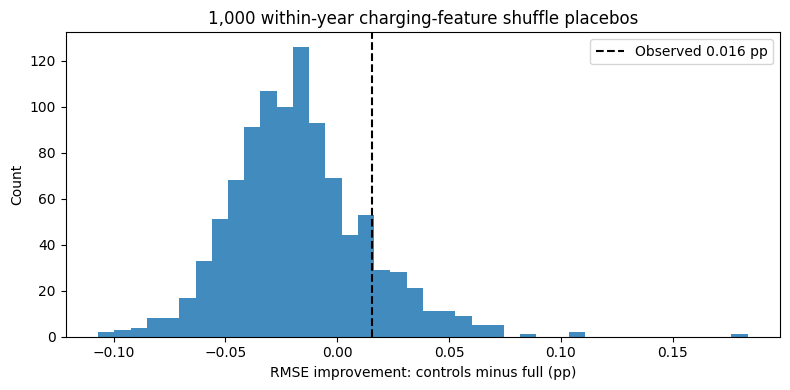

In [16]:
display(Image(filename=paths[5],width=800))

#### 7.1 · Placebo interpretation

The observed RMSE improvement is **0.016 pp**, with exploratory one-sided shuffle **p=0.132**. This is not convincing evidence that country-specific charging information drives superior forecasts. Repeating many analyses after seeing the results increases multiple-testing risk; no p-value here is presented as confirmatory.

### 8 · Dependence-aware uncertainty

A 2,000-draw bootstrap resamples **whole OOS calendar-year blocks** to keep contemporaneous country outcomes together. This addresses common-year shocks better than row-by-row bootstrap but there are only six independent year blocks; intervals are necessarily fragile. We explicitly avoid claiming a statistically significant edge.

In [17]:
print('Year-block bootstrap:',json.dumps(summary['year_block_bootstrap'],indent=2))

Year-block bootstrap: {
  "draws": 2000,
  "ci_95_rmse_improvement_pp": [
    -0.017269724451138835,
    0.052362096890466336
  ],
  "prob_improvement_exploratory": 0.817
}


### 9 · Exposure-weight sensitivity

The fixed descriptive score gives equal weight to fast and slow charging growth. We perturb fast weight uniformly between 0.2 and 0.8 in 1,000 draws and recompute yearly cross-country rank IC. This tests *analyst factor weights*, not hypothetical company revenue exposures. It cannot cure point-in-time or omitted-variable bias.

In [18]:
print('1,000 weight draws:',json.dumps(summary['weight_perturbation'],indent=2))

1,000 weight draws: {
  "draws": 1000,
  "weight_range": [
    0.2,
    0.8
  ],
  "mean_rank_ic_median": 0.04275501086073117,
  "mean_rank_ic_p05_p95": [
    0.022107685229815724,
    0.062067164475150115
  ]
}


## 11. Regime Sensitivity


### 10 · Ablation and concentration

Removing one charger feature at a time tests whether fast growth, slow growth or fast-charger mix is doing all the work. Removing Norway and China tests whether extreme adoption levels or scale dominate results. We do **not** call these ex-post winning configurations investable; they are stress tests of the predeclared primary specification.

In [19]:
display(scorecard.loc[['controls','full','no_fast','no_slow','no_mix']].round(4))
print('Regimes:',json.dumps(summary['regimes'],indent=2))

,n,rmse_pp,mae_pp,bias_pp
controls,96.0,4.4834,3.0909,-0.2328
full,96.0,4.4679,3.0788,-0.1438
no_fast,96.0,4.4905,3.0864,-0.1970
no_slow,96.0,4.4592,3.0762,-0.1550
no_mix,96.0,4.4696,3.0783,-0.1737


Regimes: {
  "pre_covid_2018_2019": {
    "n": 32,
    "delta_rmse": -0.01057881653108872
  },
  "covid_2020_2021": {
    "n": 32,
    "delta_rmse": 0.05629208307818079
  },
  "post_2022_2023": {
    "n": 32,
    "delta_rmse": -0.01211240300625338
  },
  "without_Norway": {
    "n": 90,
    "delta_rmse": -0.010895102772593646
  },
  "without_China": {
    "n": 90,
    "delta_rmse": 0.028045281786664766
  },
  "without_Norway_China": {
    "n": 84,
    "delta_rmse": 0.0018917832246092559
  }
}


#### 10.1 · Leave-one-country-out

For each country, remove its held-out forecasts **without refitting** and recompute the relative OOS error. This is an influence diagnostic, not a claim about extrapolating to a wholly unseen country. A true unseen-country test would require retraining without that country's entire history.

In [20]:
leave=country_leaveout(oos)
display(leave.sort_values('delta_rmse_control_minus_full').round(4))

,removed,n,delta_rmse_control_minus_full
11,Norway,90,-0.0109
3,Denmark,90,0.0070
0,Belgium,90,0.0076
13,Spain,90,0.0098
12,Portugal,90,0.0111
4,Finland,90,0.0128
8,Japan,90,0.0142
1,Canada,90,0.0147
10,Netherlands,90,0.0158
14,USA,90,0.0163


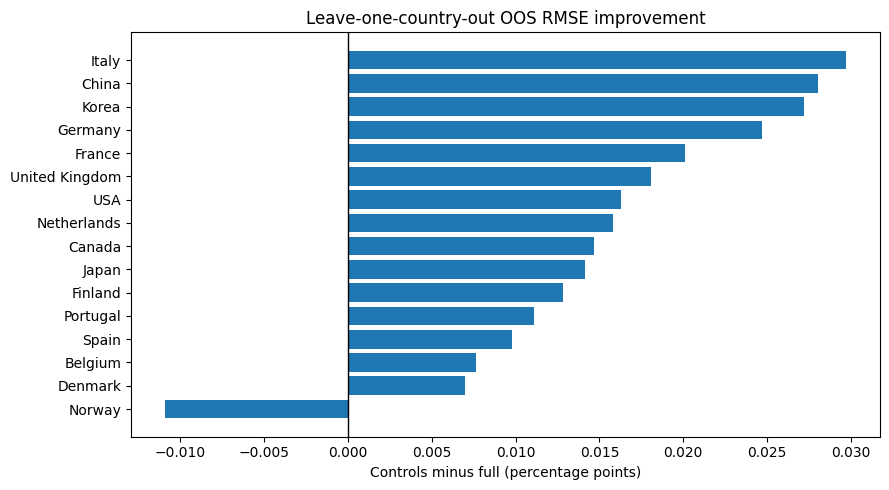

In [21]:
display(Image(filename=paths[6],width=800))

### 11 · Time-shift and horizon robustness

**Stale-signal check:** use charging growth from *t−2 vs t−3* rather than *t−1 vs t−2*. **Two-year horizon:** forecast cumulative EV sales-share change from *t−1 to t+1* using t−1 features, with an additional training embargo. The two-year target has a different scale, so its RMSE is compared only within its own horizon.

In [22]:
print('Stale charging feature RMSE:',json.dumps(summary['stale_features'],indent=2))
print('Two-year horizon RMSE:',json.dumps(summary['horizon_two'],indent=2))

Stale charging feature RMSE: {
  "controls": {
    "n": 95,
    "rmse_pp": 4.557530174646221,
    "mae_pp": 3.1626952300646645,
    "bias_pp": -0.31423412987857463
  },
  "full": {
    "n": 95,
    "rmse_pp": 4.543515540692503,
    "mae_pp": 3.165523214089016,
    "bias_pp": -0.30591361562112496
  }
}
Two-year horizon RMSE: {
  "controls": {
    "n": 80,
    "rmse_pp": 9.65868845508433,
    "mae_pp": 6.848835826056678,
    "bias_pp": -1.98791771747035
  },
  "full": {
    "n": 80,
    "rmse_pp": 9.638641729824602,
    "mae_pp": 6.8211194824525565,
    "bias_pp": -1.9179210712524166
  }
}


#### 11.1 · Forecast error by regime

Errors can be dominated by pandemic stimulus, subsidy changes, supply shortages and adoption S-curves. Year-specific mean absolute error provides a transparent view of this heterogeneity; it is not evidence that the model can detect regimes in real time.

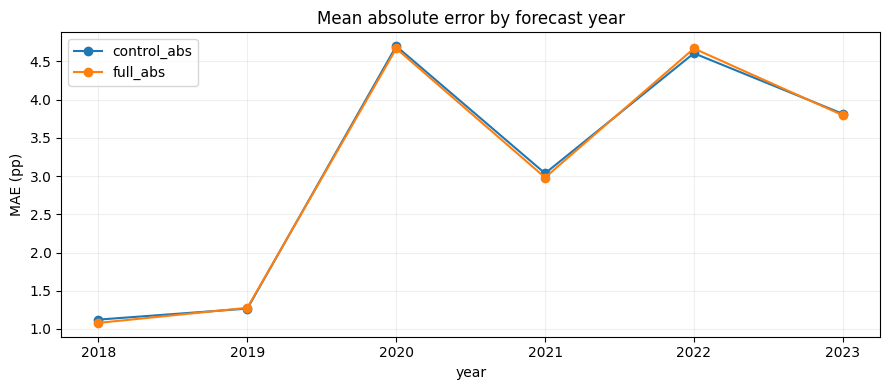

In [23]:
display(Image(filename=paths[7],width=800))

## 12. Bias Audit & Verdict


### 12 · Comprehensive bias audit

| Bias | Status and impact |
|---|---|
| Historical release vintages | **FAIL** — all historical features reconstructed from a single 2024 file; not point-in-time |
| Publication timing | Conservative t−1 feature lag, but actual historical publication timestamps not validated |
| Outcome leakage | Code uses only earlier labelled years for OOS training; tested |
| Selection/survivorship | 16 countries selected ex post for joint availability; no full-country universe |
| National definitions | Fast/slow charging classifications may vary; uptime not measured |
| Reverse causality | Charger supply may follow EV adoption; predictive not causal |
| Omitted controls | EV subsidies, vehicle affordability, battery costs, fuel prices, fleet size |
| Cross-sectional dependence | Countries share global macro and policy shocks; six OOS years |
| Multiple testing | Exploratory ablations, regimes, horizons and weight tests; no corrected discovery claim |
| Trading costs and securities | **NOT TESTED** — no issuer earnings, adjusted returns, delistings or trading strategy |

This table is a gating checklist, not a disclaimer added after an investment claim.

### 14 · Final verdict

**Industry outlook:** EV charging and transport electrification remain economically plausible growth markets, conditional on affordability, policy, utilization and infrastructure economics.

**Measured evidence:** tiny incremental improvement over controls, inferior to simple momentum, exploratory placebo not significant and year-block bootstrap crossing zero. These tests do **not** validate a reliable lead indicator.

**Alpha status:** **UNPROVEN / NOT INVESTABLE.** This study predicts country EV-sales-share change, not financial fundamentals or stock returns. Historical vintage verification and security linkage are mandatory before any investable claim.

## 13. Reproduction


### 15 · Reproducibility and attribution

Run `python -m pytest -q tests`, `python ev_charging_alpha.py`, `python plot_results.py`, and `jupyter nbconvert --execute --to notebook --inplace research.ipynb` from the study directory. The eight PNG figures, feature panel, OOS predictions, 1,000 placebo null draws and JSON metrics are deterministic under fixed seeds. All figures are generated from the included IEA-derived selected data; no simulated empirical observations are substituted.

**Attribution:** International Energy Agency (IEA), *Global EV Outlook 2024*, 23 April 2024, CC BY 4.0. Mirror: WRicd/IEA-Data-Project, `data/raw/IEA-EV-Data-2024.csv`, accessed 19 October 2026. This mirror is not an authenticated original-vintage archive. See `source_register.csv` and `data/extract_methodology.md`.

## 14. Next-Stage Protocol


### 13 · What would make this an investable study?

1. Obtain IEA/national **archived annual vintages** and publication timestamps for charger installations and registrations.
2. Add charging-point uptime, chargers per 1,000 EVs, electricity-grid capacity, subsidies, price parity and manufacturer model availability.
3. Build *issuer × geography* exposure weights from contemporaneous annual reports, split revenue between hardware, charging software, vehicles and utilities; document source dates.
4. Link lagged geography-weighted exposure to **subsequent company revenue growth** and separately to **dividend/delisting-adjusted benchmark-excess equity returns**.
5. Use purged walk-forward OOS with market/industry/momentum controls, realistic costs, exposure perturbations and company removal; pre-register a holdout and multiplicity corrections.

## 15. Sources & Artifacts


**Original sources:** IEA *Global EV Outlook 2024* (23 April 2024; CC BY 4.0), IEA Global EV Data Explorer, and an attributed 2024 third-party CSV mirror whose original-release hash is not independently verified. Exact fields, source links, vintage limits and extraction method are in `source_register.csv` and `data/extract_methodology.md`. All findings use the frozen selected 16-country extract.
